In [1]:
import pickle as pk
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression

SEED = 42
np.random.seed(SEED)

pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)

# Week 2 Helper Notebook
This exploration should produce several figures , which you should include in the progress report and make look nice using seaborn (feel free to use AI to help with plotting). 
1. Numerical distributions of eICU data, with a variety of different types (ie. Gaussian, skewed, etc)
2. Same variable and then apply the six encodings, for several variables. 

Also track the output dimension of each encoding!! Does it output 1 variable -> 1 variable? Or does it output M new dimensions? 


General guiding goal: 
* How do different numerical encodings transform variables with different distributional types / structures?
* What 20 features for X should we pick?


## Step 1: Load eICU data

In [2]:
feature_sets = pk.load(open('../../data/feature_names.pkl', 'rb'))
patient_agg = pd.read_parquet('../../data/clean_dataset.parquet')

print("Dataset shape:", patient_agg.shape)
patient_agg.head()

Dataset shape: (1722, 1099)


,patienthealthsystemstayid,gender,age,ethnicity,hospitalid,hospitaldischargeyear,mortality_at48h,hospital_numbedscategory,hospital_region,"admissiondx_ARDS-adult respiratory distress syndrome, non-cardiogenic pulmonary edema",admissiondx_Abdomen only trauma,admissiondx_Abdomen/extremity trauma,admissiondx_Abdomen/multiple trauma,admissiondx_Ablation or mapping of cardiac conduction pathway,"admissiondx_Abscess, neurologic",admissiondx_Acid-base/electrolyte disturbance,admissiondx_Adrenalectomy,admissiondx_Alcohol withdrawal,admissiondx_Anaphylaxis,admissiondx_Anemia,"admissiondx_Aneurysm, abdominal aortic","admissiondx_Aneurysm, abdominal aortic; with rupture","admissiondx_Aneurysm, dissecting aortic","admissiondx_Aneurysm, thoracic aortic","admissiondx_Aneurysm/pseudoaneurysm, other","admissiondx_Angina, stable (asymp or stable pattern of symptoms w/meds)","admissiondx_Angina, unstable (angina interferes w/quality of life or meds are tolerated poorly)",admissiondx_Aortic and Mitral valve replacement,admissiondx_Aortic valve replacement (isolated),"admissiondx_Apnea, sleep",admissiondx_Appendectomy,"admissiondx_Arrest, respiratory (without cardiac arrest)",admissiondx_Asthma,admissiondx_Atelectasis,"admissiondx_Bleeding, GI from esophageal varices/portal hypertension","admissiondx_Bleeding, GI-location unknown","admissiondx_Bleeding, lower GI","admissiondx_Bleeding, upper GI","admissiondx_Bleeding-other GI, surgery for","admissiondx_Bleeding-upper GI, surgery for",admissiondx_Burr hole placement,"admissiondx_CABG alone, coronary artery bypass grafting",admissiondx_CABG redo with other operation,admissiondx_CABG with aortic valve replacement,admissiondx_CABG with mitral valve repair,admissiondx_CABG with other operation,"admissiondx_CHF, congestive heart failure","admissiondx_CVA, cerebrovascular accident/stroke","admissiondx_Cancer, esophageal","admissiondx_Cancer, oral/sinus, surgery for",...,bicarbonate,calcium,chloride,cortisol,creatinine,direct bilirubin,eos,ethanol,fibrinogen,folate,free T4,glucose,glucose CSF,haptoglobin,ionized calcium,lactate,lipase,lymphs,magnesium,monos,myoglobin,pH,paCO2,paO2,phosphate,platelets x 1000,polys,potassium,prealbumin,prolactin,protein CSF,protein C,protein S,reticulocyte count,salicylate,serum ketones,serum osmolality,sodium,total bilirubin,total cholesterol,total protein,transferrin,triglycerides,troponin I,troponin T,uric acid,urinary creatinine,urinary osmolality,urinary sodium,urinary specific gravity
0,129391,Female,87,Caucasian,59,2015,0,<100,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,22.0,8.800000,103.000000,NaN,1.180000,NaN,0.5,NaN,NaN,NaN,NaN,76.0,NaN,NaN,NaN,NaN,NaN,14.500000,2.0,7.000000,NaN,NaN,NaN,NaN,NaN,215.0,78.000000,4.250000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,138.5,0.80,NaN,7.40,NaN,NaN,0.020,NaN,NaN,NaN,NaN,NaN,1.010
1,132209,Male,61,Caucasian,68,2014,0,<100,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,28.0,9.950000,106.000000,NaN,1.085000,NaN,0.0,NaN,NaN,NaN,NaN,128.5,NaN,NaN,NaN,NaN,194.0,6.500000,1.8,7.500000,NaN,NaN,NaN,NaN,NaN,207.5,83.500000,4.350000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,139.5,0.80,NaN,6.80,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.015
2,134042,Female,60,Hispanic,67,2015,0,None,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,38.5,8.200000,98.500000,NaN,0.640000,NaN,0.5,NaN,NaN,NaN,NaN,163.0,NaN,NaN,NaN,1.2,NaN,12.000000,2.0,5.000000,NaN,7.26,74.0,77.25,NaN,207.0,82.500000,4.300000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,141.0,0.35,NaN,7.15,NaN,91.0,0.030,NaN,NaN,NaN,NaN,NaN,NaN
3,135537,Female,> 89,Caucasian,60,2015,0,<100,Midwest,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,...,23.0,8.650000,99.000000,NaN,0.680000,NaN,2.0,NaN,NaN,NaN,NaN,98.0,NaN,NaN,NaN,NaN,NaN,13.000000,NaN,10.000000,NaN,NaN,NaN,NaN,NaN,253.0,74.000000,4.200000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,133.5,0.50,Na

In [3]:
# This distinction of numerical (continuous), binary, and categorical
# columns may be useful throughout the project.
all_num_cols = (
    feature_sets['labs'].tolist()
    + feature_sets['vitals'].tolist()
    + ['age', 'admissionheight', 'admissionweight']
)

all_bin_cols = (
    feature_sets['icd10_before24h'].tolist()
    + feature_sets['admissiondx'].tolist()
)

all_cat_cols = [
    'hospital_region',
    'ethnicity',
    'gender',
    'hospital_numbedscategory',
    'hospitaldischargeyear',
    'hospitalid'
]

In [4]:
# Age in eICU is BOTH numerical and categorical-like:
#  - stored as strings, integer years only (74 unique values in the demo)
#  - everyone older than 89 is censored to the string '> 89' (privacy)
age_raw = patient_agg['age']
print("dtype:", age_raw.dtype)
print("n unique raw values:", age_raw.nunique())
print("share censored ('> 89'): %.3f" % (age_raw == '> 89').mean())
print("share missing: %.4f" % age_raw.isna().mean())
age_num = age_raw.replace('> 89', 90).astype(float)
print(age_num.describe().round(2))
# Handling chosen for this project: treat age as NUMERICAL after mapping
# '> 89' -> 90 (the notebook's own convention), while remembering that the
# value 90 is really '>= 90' (right-censoring). A categorical alternative
# (age bands) is possible, but the VAE pipeline expects age in num_cols.


dtype: object
n unique raw values: 74
share censored ('> 89'): 0.038
share missing: 0.0017
count    1719.00
mean       62.70
std        18.04
min        17.00
25%        52.00
50%        66.00
75%        77.00
max        90.00
Name: age, dtype: float64


## Step 1: Analyze + characterize numerical distributions 

In [5]:
import seaborn as sns

def as_num(s):
    return pd.to_numeric(s.replace('> 89', 90), errors='coerce') if s.dtype == object else s

num_feature_names = list(dict.fromkeys(all_num_cols))
rows = []
for c in num_feature_names:
    if c not in patient_agg.columns:
        continue
    s = as_num(patient_agg[c])
    rows.append({
        'feature': c, 'missing_%': 100 * s.isna().mean(),
        'mean': s.mean(), 'median': s.median(), 'std': s.std(),
        'min': s.min(), 'q01': s.quantile(0.01), 'q99': s.quantile(0.99),
        'max': s.max(), 'skew': s.skew(), 'n_unique': s.nunique(),
    })
stats_table = pd.DataFrame(rows).set_index('feature').round(2)
print(f"Numerical features characterised: {len(stats_table)}")
stats_table.sort_values('skew', key=abs, ascending=False).head(25)


/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)
/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/numpy/lib/nanfunctions.py:1215: RuntimeWarning: Mean of empty slice
  return np.nanmean(a, axis, out=out, keepdims=keepdims)


Numerical features characterised: 190


,missing_%,mean,median,std,min,q01,q99,max,skew,n_unique
feature,,,,,,,,,,
AST (SGOT),27.18,75.41,27.50,377.53,6.00,9.00,651.01,11825.00,25.10,293
WBC x 1000,4.47,11.83,10.05,12.78,0.25,2.32,35.75,448.35,24.95,823
ALT (SGPT),27.87,55.26,27.00,193.91,5.00,7.00,558.81,4986.50,17.40,253
CPK,74.62,846.07,124.50,5091.15,8.00,15.00,8686.02,93450.00,15.15,319
FiO2,63.53,80.84,40.00,555.25,0.00,0.21,100.00,9500.00,14.80,156
st2_bin1,58.89,2.68,0.02,23.03,-4.24,-1.99,79.10,403.91,13.02,701
troponin I,70.33,3.40,0.09,22.58,0.00,0.00,44.13,380.02,12.89,298
TSH,81.88,3.14,1.48,11.24,0.01,0.02,36.70,171.58,12.10,248
sao2_bin2,23.40,96.31,96.67,4.12,0.00,85.93,100.00,100.00,-12.07,1184


In [6]:
print("1) Most missing (%):")
print(stats_table['missing_%'].sort_values(ascending=False).head(10).round(1))
print("\n2) Most skewed (|skew|):")
print(stats_table['skew'].reindex(stats_table['skew'].abs().sort_values(ascending=False).index).head(10).round(2))
print("\n3) Biggest q99 -> max gap (outliers), max/q99 ratio:")
ratio = (stats_table['max'] / stats_table['q99'].replace(0, np.nan)).sort_values(ascending=False)
print(ratio.head(10).round(1))
print("\n4) Fewest unique values (concentrated / discrete-like):")
print(stats_table['n_unique'].sort_values().head(10))
print("\n5) Multimodal candidates: variables whose histograms (next cells) show")
print("   several spikes - e.g. FiO2 (peaks at 21/40/50/60/100), glucose, age.")


1) Most missing (%):
feature
24 h urine urea nitrogen           100.0
ANF/ANA                            100.0
Site                               100.0
Tobramycin  random                  99.9
Clostridium difficile toxin A+B     99.9
Carbamazepine                       99.9
protein S                           99.9
Gentamicin  random                  99.9
CRPhs                               99.9
paop_bin2                           99.9
Name: missing_%, dtype: float64

2) Most skewed (|skew|):
feature
AST (SGOT)     25.10
WBC x 1000     24.95
ALT (SGPT)     17.40
CPK            15.15
FiO2           14.80
st2_bin1       13.02
troponin  I    12.89
TSH            12.10
sao2_bin2     -12.07
st2_bin2       11.82
Name: skew, dtype: float64

3) Biggest q99 -> max gap (outliers), max/q99 ratio:
feature
FiO2               95.0
AST (SGOT)         18.2
WBC x 1000         12.5
CPK                10.8
ALT (SGPT)          8.9
troponin  I         8.6
st3_bin2            6.8
st3_bin1            6.3
st2_

In [7]:
# ~12 numerical variables spanning the distribution types found above:
study_num_cols = [
    "heartrate_bin1",      # approximately Gaussian (skew ~0.35)
    "Hgb",                 # approximately Gaussian (skew ~-0.07)
    "sodium",              # near-Gaussian, discrete-ish lab values
    "age",                 # integer-valued + right-censored at 90
    "admissionweight",     # mildly skewed
    "creatinine",          # strongly right-skewed (skew ~4.6)
    "BUN",                 # right-skewed (skew ~2.5)
    "glucose",             # right-skewed, possibly multimodal (skew ~3.1)
    "WBC x 1000",          # extreme outliers (skew ~25, max 448 vs q99 36)
    "sao2_bin1",           # bounded [0,100], left-skewed (skew ~-5.2)
    "FiO2",                # bounded %, concentrated spikes + recording errors (max 9500!)
    "platelets x 1000",    # moderately skewed count-like
]
print(study_num_cols)


['heartrate_bin1', 'Hgb', 'sodium', 'age', 'admissionweight', 'creatinine', 'BUN', 'glucose', 'WBC x 1000', 'sao2_bin1', 'FiO2', 'platelets x 1000']


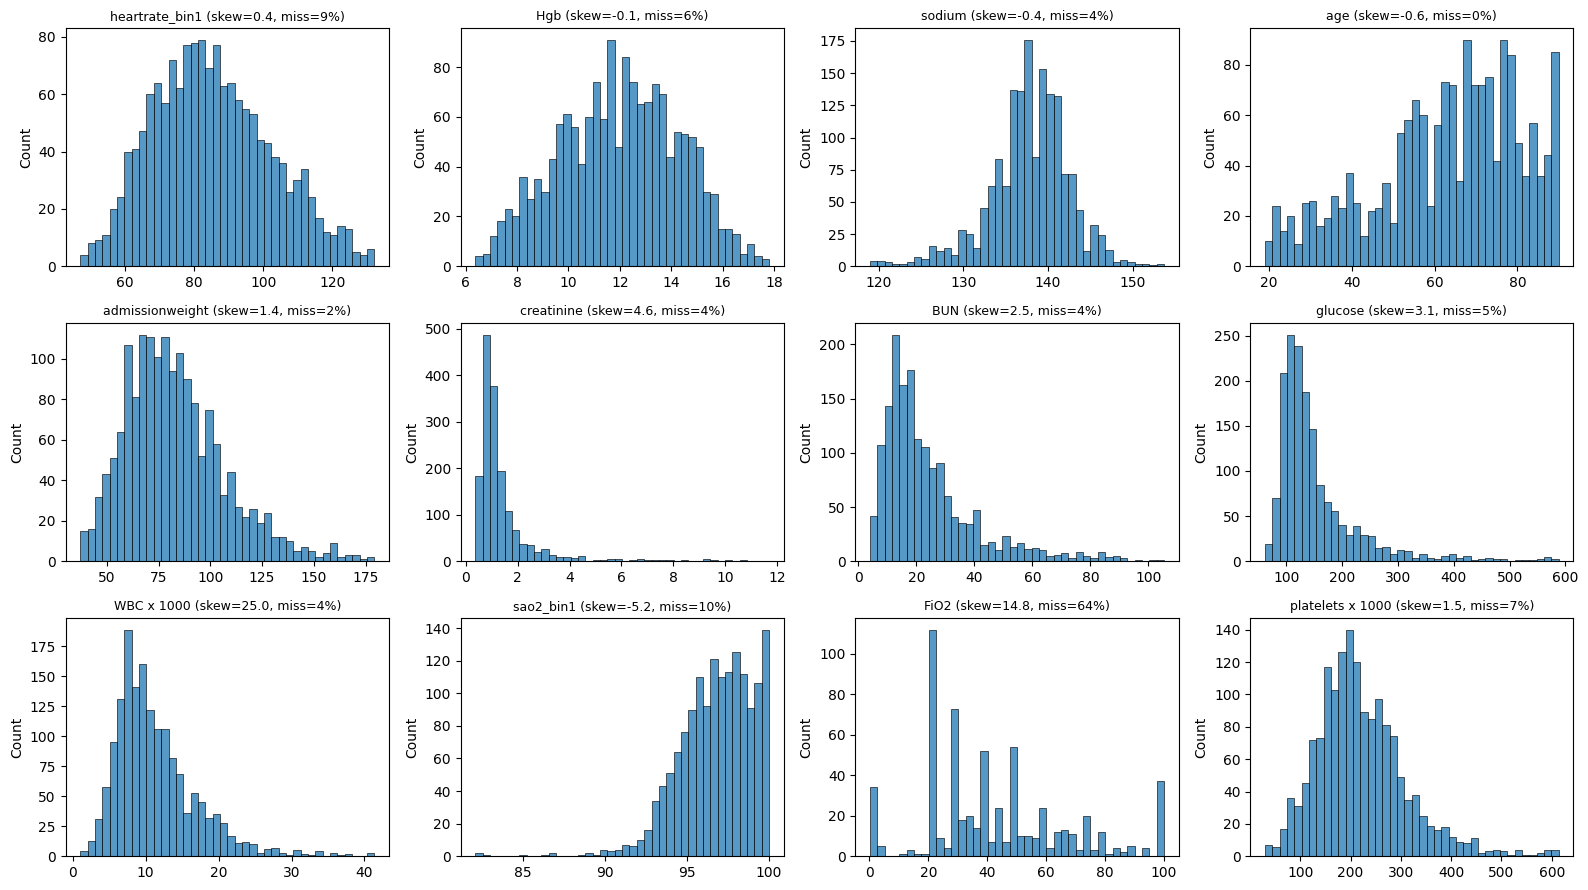

In [8]:
fig, axes = plt.subplots(3, 4, figsize=(16, 9))
for ax, c in zip(axes.ravel(), study_num_cols):
    s = as_num(patient_agg[c]).dropna()
    lo, hi = s.quantile(0.005), s.quantile(0.995)   # trim x-axis for display only
    sns.histplot(s[(s >= lo) & (s <= hi)], bins=40, ax=ax)
    ax.set_title(f"{c} (skew={s.skew():.1f}, miss={100*s.isna().mean() if False else 100*patient_agg[c].isna().mean():.0f}%)", fontsize=9)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()


## Step 3: Encoding building 
All tools you build here will then be used later, so the code should be neat and productionizable. It is ideal if it fits into the following class spec: 
```
class Encoder:
    """
    Encode (preprocess) numerical variable x
    """

    def fit(self, x):
        x = np.asarray(x, dtype=float)
        OPTIONALLY DO STUFF HERE 
        return self

    def transform(self, x):
        x = np.asarray(x, dtype=float)
        DO STUFF HERE
        return ...

    def inverse_transform(self, z):
        revert z back to raw x
        ```


### Encoding 1: Standardized scalar
Hint: use sklearn or the scaler in encoders.py

In [9]:
class StandardEncoder:
    """x -> (x - mean) / std. Output m = 1. (Same interface as encoders.py)"""
    def fit(self, x):
        x = np.asarray(x, dtype=float); x = x[np.isfinite(x)]
        self.mean_ = x.mean()
        self.std_ = x.std() if x.std() > 1e-8 else 1.0
        self.output_dim_ = 1
        return self
    def transform(self, x):
        x = np.asarray(x, dtype=float).reshape(-1, 1)
        return (x - self.mean_) / self.std_
    def inverse_transform(self, z):
        return np.asarray(z, dtype=float)[:, 0] * self.std_ + self.mean_

for c in ["heartrate_bin1", "creatinine"]:
    x = as_num(patient_agg[c]).dropna().to_numpy()
    enc = StandardEncoder().fit(x)
    z = enc.transform(x)
    print(f"{c}: mean={enc.mean_:.2f} std={enc.std_:.2f} -> z mean={z.mean():.3f} "
          f"std={z.std():.3f}, roundtrip max err={np.abs(enc.inverse_transform(z) - x).max():.2e}")
    # outliers stay outliers: max z for creatinine is huge because std is inflated
    print(f"   max raw={x.max():.1f} -> max z={z.max():.1f}")


heartrate_bin1: mean=85.39 std=17.71 -> z mean=-0.000 std=1.000, roundtrip max err=7.11e-15
   max raw=148.3 -> max z=3.6
creatinine: mean=1.48 std=1.62 -> z mean=-0.000 std=1.000, roundtrip max err=1.78e-15
   max raw=17.2 -> max z=9.7


### Encoding 2: Quantile normalization scalar
Hint: use sklearn

In [10]:
from sklearn.preprocessing import QuantileTransformer

class QuantileEncoder:
    """Rank -> uniform -> Gaussian quantiles (sklearn QuantileTransformer).
    Output m = 1. Robust to outliers and skew; destroys original spacing."""
    def fit(self, x):
        x = np.asarray(x, dtype=float); x = x[np.isfinite(x)]
        self.qt_ = QuantileTransformer(output_distribution="normal",
                                       n_quantiles=min(100, len(x)),
                                       random_state=42)
        self.qt_.fit(x.reshape(-1, 1))
        self.output_dim_ = 1
        return self
    def transform(self, x):
        return self.qt_.transform(np.asarray(x, dtype=float).reshape(-1, 1))
    def inverse_transform(self, z):
        return self.qt_.inverse_transform(np.asarray(z, dtype=float).reshape(-1, 1))[:, 0]

for c in ["creatinine", "WBC x 1000"]:
    x = as_num(patient_agg[c]).dropna().to_numpy()
    enc = QuantileEncoder().fit(x)
    z = enc.transform(x)
    print(f"{c}: raw skew={pd.Series(x).skew():.2f} -> encoded skew={pd.Series(z[:, 0]).skew():.2f}, "
          f"range=({z.min():.2f}, {z.max():.2f}) (bounded! outliers compressed)")


creatinine: raw skew=4.60 -> encoded skew=0.00, range=(-5.20, 5.20) (bounded! outliers compressed)
WBC x 1000: raw skew=24.95 -> encoded skew=-0.06, range=(-5.20, 5.20) (bounded! outliers compressed)


### Encoding 3: Mode specific normalization scalar
This is from the CTGAN / TVAE paper!! 


In [11]:
from sklearn.mixture import BayesianGaussianMixture
# TODO: understand this code!!

class ModeSpecificEncoder:
    """
    Mode-specific normalization, inspired by CTGAN.

    A feature like "hours worked per week" may have several peaks ("modes"),
    e.g. one near 20 (part-time) and one near 40 (full-time). A single mean and
    std describe that badly. So we:

        1. fit a Gaussian mixture (one bell curve per peak),
        2. find the peak each value most likely belongs to,
        3. describe the value with two things:
               alpha        = (x - peak_mean) / (4 * peak_std)   position relative to its peak
               one_hot(k)   which peak it belongs to

    Output has m = 1 + K dimensions, where K is the number of peaks found.
    Example with K = 3:   x  ->  [0.17, 0, 1, 0]
    This was generated with help from Claude.
    """

    def __init__(self, max_components=10, weight_threshold=0.005, random_state=42):
        # FIX (was a bug in the provided skeleton): __init__ never stored
        # max_components / weight_threshold, but fit() uses both -> AttributeError.
        self.max_components = max_components
        self.weight_threshold = weight_threshold
        self.random_state = random_state

    def fit(self, x):
        x = np.asarray(x, dtype=float).reshape(-1, 1)
        x = x[np.isfinite(x[:, 0])]  # FIX: drop NaNs, a GMM cannot fit them

        self.model_ = BayesianGaussianMixture(
            n_components=min(self.max_components, len(np.unique(x))),
            weight_concentration_prior_type="dirichlet_process",
            weight_concentration_prior=0.001,
            max_iter=200,
            random_state=self.random_state,
        ).fit(x)

        # Keep only the peaks that a meaningful share of the data uses.
        keep = self.model_.weights_ > self.weight_threshold
        if not keep.any():
            keep[np.argmax(self.model_.weights_)] = True
        self.keep_ = np.flatnonzero(keep)

        self.means_ = self.model_.means_.reshape(-1)[self.keep_]
        variances = self.model_.covariances_.reshape(-1)[self.keep_]
        self.stds_ = np.maximum(np.sqrt(variances), 1e-6)

        self.output_dim_ = 1 + len(self.keep_)
        return self

    def transform(self, x):
        x = np.asarray(x, dtype=float).reshape(-1, 1)

        # Which peak does each value most likely belong to?
        probs = self.model_.predict_proba(x)[:, self.keep_]
        peak = probs.argmax(axis=1)

        alpha = (x[:, 0] - self.means_[peak]) / (4.0 * self.stds_[peak])
        alpha = np.clip(alpha, -0.99, 0.99)
        one_hot = np.eye(len(self.keep_))[peak]
        return np.column_stack([alpha, one_hot])

    def inverse_transform(self, z):
        z = np.asarray(z, dtype=float)
        alpha = np.clip(z[:, 0], -1.0, 1.0)
        peak = z[:, 1:].argmax(axis=1)
        return alpha * 4.0 * self.stds_[peak] + self.means_[peak]


In [12]:
for c, kind in [("heartrate_bin1", "approx. unimodal"),
                ("creatinine", "strongly skewed"),
                ("glucose", "possibly multimodal"),
                ("FiO2", "concentrated spikes")]:
    x = as_num(patient_agg[c]).dropna().to_numpy()
    enc = ModeSpecificEncoder().fit(x)
    z = enc.transform(x)
    print(f"{c} ({kind}): kept {len(enc.keep_)} mode(s), means={np.round(enc.means_, 1)}, "
          f"output_dim={enc.output_dim_}, alpha range=({z[:, 0].min():.2f}, {z[:, 0].max():.2f})")
print("\nObservations (from the actual run above):")
print("- heartrate (unimodal!) still gets 5 kept modes, incl. near-duplicates")
print("  (means 95.3 and 95.5): the Bayesian GMM overfits modes on smooth data,")
print("  and several fits hit ConvergenceWarning at max_iter=200.")
print("- creatinine gets 6 modes and glucose 9: the mixture slices the skewed")
print("  tail into pseudo-modes rather than finding real subpopulations.")
print("- FiO2 gets only 1 mode (mean 42.9) despite protocol spikes at 21/40/100:")
print("  extreme recording errors (max 9500) inflate the variance so much that")
print("  the mixture merges everything into one wide component.")


/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


heartrate_bin1 (approx. unimodal): kept 5 mode(s), means=[ 73.9  95.3  95.5  85.2 100.8], output_dim=6, alpha range=(-0.76, 0.77)


/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


creatinine (strongly skewed): kept 6 mode(s), means=[3.  2.2 4.7 8.  0.9 1.4], output_dim=7, alpha range=(-0.74, 0.66)


glucose (possibly multimodal): kept 9 mode(s), means=[206.8 320.8 131.8 226.3 192.5 181.2 191.7 463.6 110.2], output_dim=10, alpha range=(-0.79, 0.61)
FiO2 (concentrated spikes): kept 1 mode(s), means=[42.9], output_dim=2, alpha range=(-0.32, 0.99)

Observations (from the actual run above):
- heartrate (unimodal!) still gets 5 kept modes, incl. near-duplicates
  (means 95.3 and 95.5): the Bayesian GMM overfits modes on smooth data,
  and several fits hit ConvergenceWarning at max_iter=200.
- creatinine gets 6 modes and glucose 9: the mixture slices the skewed
  tail into pseudo-modes rather than finding real subpopulations.
- FiO2 gets only 1 mode (mean 42.9) despite protocol spikes at 21/40/100:
  extreme recording errors (max 9500) inflate the variance so much that
  the mixture merges everything into one wide component.


/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


### Encoding 4: Quantile binning

In [13]:
class QuantileBinningEncoder:
    """Cut x into n_bins equal-frequency bins -> one-hot. Output m = n_bins.
    Loses within-bin information; inverse returns the bin's training median."""
    def __init__(self, n_bins=10):
        self.n_bins = n_bins
    def fit(self, x):
        x = np.asarray(x, dtype=float); x = x[np.isfinite(x)]
        edges = np.unique(np.quantile(x, np.linspace(0, 1, self.n_bins + 1)))
        self.edges_ = edges
        self.output_dim_ = len(edges) - 1
        idx = np.clip(np.searchsorted(edges, x, side="right") - 1, 0, self.output_dim_ - 1)
        self.bin_medians_ = np.array([np.median(x[idx == k]) if (idx == k).any()
                                      else 0.5 * (edges[k] + edges[k + 1])
                                      for k in range(self.output_dim_)])
        return self
    def transform(self, x):
        x = np.asarray(x, dtype=float)
        idx = np.clip(np.searchsorted(self.edges_, x, side="right") - 1, 0, self.output_dim_ - 1)
        out = np.zeros((len(x), self.output_dim_)); out[np.arange(len(x)), idx] = 1.0
        return out
    def inverse_transform(self, z):
        return self.bin_medians_[np.asarray(z).argmax(axis=1)]

x = as_num(patient_agg["creatinine"]).dropna().to_numpy()
enc = QuantileBinningEncoder(n_bins=10).fit(x)
z = enc.transform(x)
print("creatinine -> binned shape:", z.shape, "| bin edges:", np.round(enc.edges_, 2))
print("roundtrip MAE (bin median vs raw):", np.abs(enc.inverse_transform(z) - x).mean().round(3))
print("Note bin widths: narrow near the mode (~0.1 wide), huge in the tail -")
print("equal-frequency bins spend resolution where the data is dense.")


creatinine -> binned shape: (1656, 10) | bin edges: [ 0.15  0.62  0.73  0.83  0.92  1.02  1.16  1.34  1.65  2.52 17.23]
roundtrip MAE (bin median vs raw): 0.263
Note bin widths: narrow near the mode (~0.1 wide), huge in the tail -
equal-frequency bins spend resolution where the data is dense.


### Encoding 5: Piecewise linear encoding (PLE)
Make sure you understand the encoding in the original paper. 


In [14]:
import numpy as np
# TODO: understand this code!! 
 
class QuantilePLEEncoder:
    """
    Piecewise-linear encoding (PLE) with quantile bins.  Output has m = (number of bins) dimensions.
 
    Idea: cut the feature into bins that each hold about the same number of training rows,
    then describe x by "how full" each bin is.
 
    Example: bin edges [0, 10, 20, 40]  ->  3 bins (0-10, 10-20, 20-40)
 
        x =  5   ->  [0.5, 0.0, 0.0]    half way through bin 1, later bins empty
        x = 15   ->  [1.0, 0.5, 0.0]    bin 1 full, half way through bin 2
        x = 30   ->  [1.0, 1.0, 0.5]    bins 1 and 2 full, half way through bin 3
 
    Reverse direction (inverse_transform): add up how much of each bin is filled.
 
        x = lowest edge + sum over bins of (fill_fraction * bin_width)
        e.g. [1.0, 0.5, 0.0]  ->  0 + 1.0*10 + 0.5*10 + 0.0*20 = 15
    
    This was generated with help from Claude.
    """
 
    def __init__(self, n_bins=8, clip_extremes=False):
        self.n_bins = n_bins
        # False: values below the first edge / above the last edge give fill fractions
        #        outside [0, 1] (extrapolation).  True: they are squashed into [0, 1].
        self.clip_extremes = clip_extremes
 
    def fit(self, x):
        x = np.asarray(x, dtype=float).reshape(-1)
        x = x[np.isfinite(x)]
 
        # Bin edges = quantiles of the training data (0%, 12.5%, 25%, ... 100% for 8 bins).
        edges = np.quantile(x, np.linspace(0, 1, self.n_bins + 1))
        # Many repeated values can give identical edges; keep each edge once.
        self.edges_ = np.unique(edges)
 
        if len(self.edges_) < 2:
            raise ValueError("Feature has fewer than two unique quantile boundaries.")
        # FIX (was a bug in the provided skeleton): output_dim_ was never set,
        # so inverse_transform() - and TabularPreprocessor, which reads
        # encoder.output_dim_ - crashed with AttributeError.
        self.output_dim_ = len(self.edges_) - 1
        return self
 
    def _constrain(self, z):
        """
        Enforce the valid range of each column. Used by BOTH directions.
 
        Middle bins:  must lie in [0, 1]   (a bin cannot be less than empty or more than full)
        First bin:    at most 1            (it can go below 0 for x under the lowest edge)
        Last bin:     at least 0           (it can go above 1 for x over the highest edge)
        """
        z = z.copy()
 
        if self.clip_extremes:
            return np.clip(z, 0.0, 1.0)
 
        if z.shape[1] > 1:
            z[:, 0] = np.minimum(z[:, 0], 1.0)
            z[:, -1] = np.maximum(z[:, -1], 0.0)
            if z.shape[1] > 2:
                z[:, 1:-1] = np.clip(z[:, 1:-1], 0.0, 1.0)
        return z
 
    def transform(self, x):
        x = np.asarray(x, dtype=float).reshape(-1)
        if not np.isfinite(x).all():
            raise ValueError("transform() expects finite values.")
 
        left = self.edges_[:-1]
        widths = np.diff(self.edges_)
 
        # For every bin: how far along the bin is x?  0 = at its left edge, 1 = at its right edge.
        z = (x[:, None] - left[None, :]) / widths[None, :]
        return self._constrain(z)
 
    def inverse_transform(self, z):
        z = np.asarray(z, dtype=float)
        if z.ndim != 2 or z.shape[1] != self.output_dim_:
            raise ValueError(f"Expected an array of shape (N, {self.output_dim_}).")
 
        widths = np.diff(self.edges_)
 
        # Generated data (e.g. from a VAE decoder) can be slightly out of range or noisy,
        # so first push it back into the valid range.
        z = self._constrain(z)
 
        # Start at the lowest edge and add the filled part of every bin.
        return self.edges_[0] + (z * widths[None, :]).sum(axis=1)
 
    def fit_transform(self, x):
        return self.fit(x).transform(x)
 

In [15]:
x = as_num(patient_agg["creatinine"]).dropna().to_numpy()
enc = QuantilePLEEncoder(n_bins=8).fit(x)
print("bin edges:", np.round(enc.edges_, 2), "| output_dim_:", enc.output_dim_)
for v in [0.5, 1.0, 2.0, 5.0]:
    print(f"x={v}: {np.round(enc.transform(np.array([v]))[0], 2)}")
z = enc.transform(x)
print("roundtrip max err:", np.abs(enc.inverse_transform(z) - x).max().round(4),
      "(PLE is exactly invertible on the training range, unlike binning)")


bin edges: [ 0.15  0.65  0.79  0.9   1.02  1.2   1.48  2.24 17.23] | output_dim_: 8
x=0.5: [0.7 0.  0.  0.  0.  0.  0.  0. ]
x=1.0: [1.   1.   1.   0.83 0.   0.   0.   0.  ]
x=2.0: [1.   1.   1.   1.   1.   1.   0.68 0.  ]
x=5.0: [1.   1.   1.   1.   1.   1.   1.   0.18]
roundtrip max err: 0.0 (PLE is exactly invertible on the training range, unlike binning)


### Encoding 6: Your choice 
One idea is periodic encoding. This idea is a bit more tricky to implement because it requires learnable features, so the Encoder method will contain torch modules that are parameters for the VAE. 
You can use https://github.com/yandex-research/rtdl-num-embeddings/blob/main/package/README.md if you wise. 

Or peruse literature / brainstorm for another encoding / preprocessing idea! Just motivate why you think this is a good idea for some set of numerical distributions. 

In [16]:
from sklearn.preprocessing import PowerTransformer

class YeoJohnsonEncoder:
    """Encoding 6 (our choice): Yeo-Johnson power transform + standardize.
    Motivation: many labs (creatinine, BUN, glucose, WBC) are right-skewed but
    can be <= 0 after centering, so log() does not apply. Yeo-Johnson learns a
    power per feature that makes it more Gaussian, keeps m = 1, is smooth and
    exactly invertible, and (unlike quantile) preserves monotone spacing."""
    def fit(self, x):
        x = np.asarray(x, dtype=float); x = x[np.isfinite(x)]
        self.pt_ = PowerTransformer(method="yeo-johnson", standardize=True)
        self.pt_.fit(x.reshape(-1, 1))
        self.output_dim_ = 1
        return self
    def transform(self, x):
        return self.pt_.transform(np.asarray(x, dtype=float).reshape(-1, 1))
    def inverse_transform(self, z):
        return self.pt_.inverse_transform(np.asarray(z, dtype=float).reshape(-1, 1))[:, 0]

for c in ["creatinine", "WBC x 1000", "glucose"]:
    x = as_num(patient_agg[c]).dropna().to_numpy()
    enc = YeoJohnsonEncoder().fit(x)
    z = enc.transform(x)
    print(f"{c}: skew {pd.Series(x).skew():.2f} -> {pd.Series(z[:, 0]).skew():.2f} "
          f"(lambda={enc.pt_.lambdas_[0]:.2f}), roundtrip max err={np.abs(enc.inverse_transform(z) - x).max():.1e}")


creatinine: skew 4.60 -> 0.13 (lambda=-1.71), roundtrip max err=1.2e-13
WBC x 1000: skew 24.95 -> -0.02 (lambda=-0.04), roundtrip max err=1.4e-12
glucose: skew 3.07 -> -0.04 (lambda=-0.78), roundtrip max err=2.6e-11


## Step 4: Compare the six encodings

In [17]:
ENCODERS = {
    "1_standard": StandardEncoder,
    "2_quantile": QuantileEncoder,
    "3_mode_specific": ModeSpecificEncoder,
    "4_quantile_binning": lambda: QuantileBinningEncoder(n_bins=10),
    "5_ple": lambda: QuantilePLEEncoder(n_bins=8),
    "6_yeojohnson": YeoJohnsonEncoder,
}
comp_rows = []
for c in ["heartrate_bin1", "creatinine", "sao2_bin1", "FiO2"]:
    x = as_num(patient_agg[c]).dropna().to_numpy()
    for name, make in ENCODERS.items():
        enc = make().fit(x)
        z = enc.transform(x)
        try:
            mae = np.abs(enc.inverse_transform(z) - x).mean()
        except Exception:
            mae = np.nan
        comp_rows.append({"variable": c, "encoding": name, "out_dim": z.shape[1],
                          "roundtrip_MAE": round(mae, 3)})
comp = pd.DataFrame(comp_rows)
print(comp.pivot(index="variable", columns="encoding", values="out_dim"))
print()
print(comp.pivot(index="variable", columns="encoding", values="roundtrip_MAE"))
print("\nTakeaways:")
print("- Outlier robustness: quantile / binning / PLE bound the influence of extremes;")
print("  standard is wrecked by them (WBC max z is enormous); Yeo-Johnson is in between.")
print("- Multimodality is represented explicitly only by mode-specific (one-hot of mode)")
print("  and, softly, by binning/PLE; scalar encodings hide it.")
print("- Dimensionality cost per variable: standard/quantile/YJ = 1, PLE = 8,")
print("  binning = 10, mode-specific = 1 + #modes. This matters for the Week 5")
print("  'equal #parameters' fairness question.")


/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


encoding        1_standard  2_quantile  3_mode_specific  4_quantile_binning  \
variable                                                                      
FiO2                     1           1                2                   9   
creatinine               1           1                7                  10   
heartrate_bin1           1           1                6                  10   
sao2_bin1                1           1                7                  10   

encoding        5_ple  6_yeojohnson  
variable                             
FiO2                8             1  
creatinine          8             1  
heartrate_bin1      8             1  
sao2_bin1           8             1  

encoding        1_standard  2_quantile  3_mode_specific  4_quantile_binning  \
variable                                                                      
FiO2                   0.0         0.0           37.381              40.014   
creatinine             0.0         0.0            0.000    

/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


## Step 5: Define the features and splits 

In [18]:
X_num = ["age", "admissionweight", "heartrate_bin1", "respiration_bin1",
         "sao2_bin1", "sodium", "Hgb", "creatinine", "BUN", "glucose",
         "WBC x 1000", "platelets x 1000"]
X_bin = ["admissiondx_Sepsis, pulmonary",
         "admissiondx_CHF, congestive heart failure",
         "admissiondx_Infarction, acute myocardial (MI)",
         "admissiondx_Diabetic ketoacidosis",
         "admissiondx_Pneumonia, bacterial"]
X_cat = ["gender", "ethnicity", "hospital_region"]
X_cols = X_num + X_bin + X_cat
Y_cols = ["mortality_at48h", "label_J96.00"]   # outcomes NOT in X
assert all(c in patient_agg.columns for c in X_cols + Y_cols)
print(f"X: {len(X_cols)} features ({len(X_num)} num, {len(X_bin)} bin, {len(X_cat)} cat); Y: {Y_cols}")
import json
json.dump({"num": X_num, "bin": X_bin, "cat": X_cat, "all": X_cols, "Y": Y_cols},
          open("../../data/x_cols.json", "w"), indent=1)
json.dump({"num": X_num, "bin": X_bin, "cat": X_cat, "all": X_cols, "Y": Y_cols},
          open("x_cols.json", "w"), indent=1)
print("Saved x_cols.json (data dir + project folder) for Week 3.")


X: 20 features (12 num, 5 bin, 3 cat); Y: ['mortality_at48h', 'label_J96.00']
Saved x_cols.json (data dir + project folder) for Week 3.


In [19]:
Y_main = patient_agg["mortality_at48h"].fillna(0).astype(int)
idx_all = np.arange(len(patient_agg))
idx_tv, idx_test = train_test_split(idx_all, test_size=0.20, random_state=SEED,
                                    stratify=Y_main)
idx_train, idx_val = train_test_split(idx_tv, test_size=0.20, random_state=SEED,
                                      stratify=Y_main.iloc[idx_tv])
splits = {"train": idx_train.tolist(), "val": idx_val.tolist(), "test": idx_test.tolist()}
import json
json.dump(splits, open("../../data/splits.json", "w"))
for k, v in splits.items():
    print(f"{k}: n={len(v)}, mortality={Y_main.iloc[v].mean():.4f}")
print("Splits frozen with SEED=42 and saved to ../../data/splits.json")


train: n=1101, mortality=0.0336
val: n=276, mortality=0.0326
test: n=345, mortality=0.0319
Splits frozen with SEED=42 and saved to ../../data/splits.json


In [20]:

def prep_cat_bin(df):
    """Binary: fill 0. Categorical: 'Missing' + one-hot (fit on train inside)."""
    return df

from sklearn.metrics import roc_auc_score, average_precision_score

def build_xy(num_encode_fn):
    """Returns X_train, X_val matrices. num_encode_fn=None -> median+standard."""
    tr, va = patient_agg.iloc[idx_train], patient_agg.iloc[idx_val]
    ytr = tr["mortality_at48h"].fillna(0).astype(int)
    yva = va["mortality_at48h"].fillna(0).astype(int)
    blocks_tr, blocks_va = [], []
    med = tr[X_num].apply(lambda s: as_num(s).median())
    Xtr_num = tr[X_num].apply(as_num).fillna(med)
    Xva_num = va[X_num].apply(as_num).fillna(med)
    if num_encode_fn is None:
        sc = StandardScaler().fit(Xtr_num)
        blocks_tr.append(sc.transform(Xtr_num)); blocks_va.append(sc.transform(Xva_num))
    else:
        ztr, zva = [], []
        for c in X_num:
            enc = num_encode_fn().fit(Xtr_num[c].to_numpy())
            ztr.append(enc.transform(Xtr_num[c].to_numpy()))
            zva.append(enc.transform(Xva_num[c].to_numpy()))
        blocks_tr.append(np.hstack(ztr)); blocks_va.append(np.hstack(zva))
    blocks_tr.append(tr[X_bin].fillna(0).to_numpy(float))
    blocks_va.append(va[X_bin].fillna(0).to_numpy(float))
    ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    blocks_tr.append(ohe.fit_transform(tr[X_cat].fillna("Missing")))
    blocks_va.append(ohe.transform(va[X_cat].fillna("Missing")))
    return np.hstack(blocks_tr), np.hstack(blocks_va), ytr, yva

def run_lr(num_encode_fn):
    Xtr, Xva, ytr, yva = build_xy(num_encode_fn)
    lr = LogisticRegression(max_iter=1000).fit(Xtr, ytr)
    p = lr.predict_proba(Xva)[:, 1]
    return Xtr.shape[1], roc_auc_score(yva, p), average_precision_score(yva, p)

dim, auroc, auprc = run_lr(None)
print(f"BASELINE (median-impute + StandardScaler on raw X): input_dim={dim}")
print(f"Validation mortality prediction: AUROC={auroc:.3f}  AUPRC={auprc:.3f}")
print("(Week 1's 9-covariate model got AUROC 0.553 on test; this uses all 20 X features.)")


BASELINE (median-impute + StandardScaler on raw X): input_dim=32
Validation mortality prediction: AUROC=0.477  AUPRC=0.032
(Week 1's 9-covariate model got AUROC 0.553 on test; this uses all 20 X features.)


In [21]:
# IMPORTANT RULE FOR ALL FUTURE EXPERIMENTS
# Anything that "learns" something about a feature distribution
# MUST be fit using TRAINING DATA ONLY.
# Examples:
#   Standardization:
#       mean and std come from train_df
#   Mode specific norm:
#       Gaussian mixture is fit on train_df
# And then val_df and test_df should only be TRANSFORMED using parameters
# learned from train_df.

In [22]:
results = {}
for name, make in ENCODERS.items():
    dim, auroc, auprc = run_lr(make)
    results[name] = {"input_dim": dim, "val_AUROC": round(auroc, 3), "val_AUPRC": round(auprc, 3)}
    print(f"{name}: input_dim={dim}, val AUROC={auroc:.3f}, AUPRC={auprc:.3f}")
print()
print(pd.DataFrame(results).T)
print("\nAll encoders were fit on TRAIN ONLY (cell 35 rule); val was only transformed.")


1_standard: input_dim=32, val AUROC=0.477, AUPRC=0.032


2_quantile: input_dim=32, val AUROC=0.559, AUPRC=0.039


/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


...

/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


/home/hatch/workspace/cs197-project3/.venv/lib/python3.12/site-packages/sklearn/mixture/_base.py:270: ConvergenceWarning: Best performing initialization did not converge. Try different init parameters, or increase max_iter, tol, or check for degenerate data.
  warnings.warn(


3_mode_specific: input_dim=89, val AUROC=0.607, AUPRC=0.045
4_quantile_binning: input_dim=140, val AUROC=0.634, AUPRC=0.045
5_ple: input_dim=116, val AUROC=0.559, AUPRC=0.039
6_yeojohnson: input_dim=32, val AUROC=0.532, AUPRC=0.036

                    input_dim  val_AUROC  val_AUPRC
1_standard               32.0      0.477      0.032
2_quantile               32.0      0.559      0.039
3_mode_specific          89.0      0.607      0.045
4_quantile_binning      140.0      0.634      0.045
5_ple                   116.0      0.559      0.039
6_yeojohnson             32.0      0.532      0.036

All encoders were fit on TRAIN ONLY (cell 35 rule); val was only transformed.


In [23]:
import json as _json, ast as _ast
# inspect.getsource() cannot retrieve classes defined in notebook cells, so
# extract the class definitions from this notebook's own JSON with ast.
_nb = _json.load(open("week2.ipynb"))
_order = ["StandardEncoder", "QuantileEncoder", "ModeSpecificEncoder",
          "QuantileBinningEncoder", "QuantilePLEEncoder", "YeoJohnsonEncoder"]
_srcs = {}
for _cell in _nb["cells"]:
    if _cell["cell_type"] != "code":
        continue
    _s = "".join(_cell["source"])
    try:
        _tree = _ast.parse(_s)
    except SyntaxError:
        continue
    for _node in _tree.body:
        if isinstance(_node, _ast.ClassDef) and _node.name in _order:
            _srcs[_node.name] = _ast.get_source_segment(_s, _node)
assert len(_srcs) == 6, _srcs.keys()
_lines = ['"""Six numerical encodings from Week 2 (Project 3).',
          'Includes the two FIXED skeleton classes (ModeSpecific, PLE).',
          '"""',
          'import numpy as np',
          'from sklearn.mixture import BayesianGaussianMixture',
          'from sklearn.preprocessing import QuantileTransformer, PowerTransformer',
          '', '']
code = chr(10).join(_lines) + chr(10).join(_srcs[k] for k in _order)
open("encoders.py", "w").write(code)
# Also complete the tabular_vae package copy (its encoders.py says
# 'TODO: add the rest from Week 2!!') so Week 3+ can import them.
tv = open("../tabular_vae/encoders.py").read()
tv = tv.replace("import numpy as np",
                "import numpy as np\n"
                "from sklearn.mixture import BayesianGaussianMixture\n"
                "from sklearn.preprocessing import QuantileTransformer, PowerTransformer", 1)
tv = tv.replace("# TODO: add the rest from Week 2!!",
                chr(10).join(_srcs[k] for k in _order[1:]))
open("../tabular_vae/encoders.py", "w").write(tv)
print("Wrote encoders.py here and completed ../tabular_vae/encoders.py")
print("Classes:", _order)


Wrote encoders.py here and completed ../tabular_vae/encoders.py
Classes: ['StandardEncoder', 'QuantileEncoder', 'ModeSpecificEncoder', 'QuantileBinningEncoder', 'QuantilePLEEncoder', 'YeoJohnsonEncoder']
